## 1. Preprocessing

First we load the emotion scores and your answers from the reviewing app.
Use one final ratings CSV, not the balanced copy or two overlapping reviewers.
Put `observer_annotations.csv` in the TriAid folder or change its path below.

In [ ]:
from pathlib import Path
from datetime import datetime
from zipfile import ZipFile, ZIP_DEFLATED
import copy
import io
import json
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    average_precision_score,
    roc_auc_score,
    f1_score,
    fbeta_score,
)
from IPython.display import display

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
PROJECT = Path('/content/drive/MyDrive/TriAid')
DATA_PATH = PROJECT / 'data' / 'DAiSEE.zip'
LABELS_PATH = PROJECT / 'observer_annotations.csv'
RESULTS = PROJECT / 'simple_gru_results' / datetime.now().strftime('%Y%m%d_%H%M%S')
EMOTIONS = ['boredom', 'engagement', 'confusion', 'frustration']
SEED = 42
SEEDS = [42, 143, 244]
TARGET_RECALL = 0.9
MISS_COST = 5
torch.set_num_threads(min(4, os.cpu_count() or 1))
RESULTS.mkdir(parents=True, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# the video names have .avi on the end, take that off so the IDs match
def clean_ids(column):
    return (
        column.astype(str)
        .str.strip()
        .str.replace('\\.(avi|mp4|mov|mkv)$', '', case=False, regex=True)
    )

In [ ]:
# this reads the score files, not the videos
def read_emotions(path):
    filenames = {
        'trainlabels.csv': 'train',
        'validationlabels.csv': 'val',
        'vallabels.csv': 'val',
        'testlabels.csv': 'test',
    }
    tables = []

    def add_table(text, split):
        table = pd.read_csv(io.StringIO(text), dtype=str)
        table.columns = table.columns.str.strip().str.lower()
        table['clip_id'] = clean_ids(table['clipid'])
        table['split'] = split
        tables.append(table[['clip_id', 'split'] + EMOTIONS])

    # the zip stays zipped, we only open its CSV files
    if path.is_file() and path.suffix.lower() == '.zip':
        with ZipFile(path) as archive:
            names = archive.namelist()
            train_files = [
                name
                for name in names
                if ('/' + name.lower()).endswith('/labels/trainlabels.csv')
                and 'gender' not in name.lower()
            ]
            if len(train_files) != 1:
                raise ValueError('Choose a ZIP containing one DAiSEE Labels folder.')
            labels_folder = train_files[0].rsplit('/', 1)[0].lower()
            for name in names:
                folder, _, filename = name.rpartition('/')
                if folder.lower() == labels_folder and filename.lower() in filenames:
                    add_table(
                        archive.read(name).decode('utf-8-sig'),
                        filenames[filename.lower()],
                    )

    # this also works if the dataset was already extracted
    elif path.is_dir():
        train_files = [
            file
            for file in path.rglob('*')
            if file.name.lower() == 'trainlabels.csv'
            and file.parent.name.lower() == 'labels'
            and ('gender' not in str(file).lower())
        ]
        if len(train_files) != 1:
            raise ValueError('Choose a folder containing one DAiSEE Labels folder.')
        for file in train_files[0].parent.iterdir():
            if file.name.lower() in filenames:
                add_table(
                    file.read_text(encoding='utf-8-sig'), filenames[file.name.lower()]
                )
    else:
        raise FileNotFoundError(f'DAiSEE source not found: {path}')
    emotions = pd.concat(tables, ignore_index=True)

    if emotions.clip_id.duplicated().any():
        raise ValueError('Duplicate clip IDs in the DAiSEE label files.')
    emotions[EMOTIONS] = emotions[EMOTIONS].apply(pd.to_numeric)

    if not np.isin(emotions[EMOTIONS].to_numpy(), [0, 1, 2, 3]).all():
        raise ValueError('Expected DAiSEE emotion labels from 0 to 3.')
    return emotions

In [ ]:
emotions = read_emotions(DATA_PATH)

if not LABELS_PATH.is_file():
    raise FileNotFoundError('Set LABELS_PATH to your observer_annotations.csv file.')

# these are the answers from the clip reviewing app
labels = pd.read_csv(LABELS_PATH, dtype=str).fillna('')
labels.columns = labels.columns.str.strip().str.lower()
required = {
    'clip_id',
    'subject',
    'check_in_warranted',
    'annotation_status',
    'label_source',
}

if not required.issubset(labels.columns):
    raise ValueError(f'The annotations CSV needs these columns: {sorted(required)}')

In [ ]:
# make sure each clip is only counted once
labels['clip_id'] = clean_ids(labels['clip_id'])

if labels.clip_id.duplicated().any():
    raise ValueError('Use one row per clip; do not combine overlapping ratings.')

if not labels.label_source.eq('visual_observer_proxy').all():
    raise ValueError(
        'Use independent human annotations, not heuristic-generated labels.'
    )

if not labels.annotation_status.isin(['labelled', 'unsure', 'unreadable']).all():
    raise ValueError('An annotation has an unknown status.')

In [ ]:
print('Unsure/unreadable rows left out:', labels.annotation_status.ne('labelled').sum())
labels = labels.loc[labels.annotation_status.eq('labelled')].copy()

if not labels.check_in_warranted.isin(['0', '1']).all():
    raise ValueError('Check-in labels must be 0 or 1.')

Unsure/unreadable rows left out: 0


In [ ]:
# we need the student ID to keep the groups seperate
labels['subject'] = labels.subject.str.strip()

if labels.subject.eq('').any():
    raise ValueError('Each rating needs a student ID for grouped evaluation.')

if not labels.clip_id.str[:6].eq(labels.subject).all():
    raise ValueError('A student ID disagrees with its DAiSEE clip ID.')

In [ ]:
labels = labels.rename(columns={'split': 'review_split'})

# match each clip with the answer you gave it
data = labels.merge(
    emotions, on='clip_id', how='left', validate='one_to_one', indicator=True
)

if data._merge.ne('both').any():
    raise ValueError('Some reviewed clips are missing from the DAiSEE label files.')

if 'review_split' in data:
    review_split = data.review_split.str.lower().replace(
        {'training': 'train', 'validation': 'val', 'testing': 'test'}
    )

    if not review_split.eq(data.split).all():
        raise ValueError("A review's split disagrees with its DAiSEE label file.")
print('Matched labeled clips by official split:')
display(data.groupby('split').size().rename('clips').to_frame())

Matched labeled clips by official split:


,clips
split,
train,274


In [ ]:
# leave the official validation and test clips out of fitting
reserved = data.loc[data.split.ne('train')].copy()
data = data.loc[data.split.eq('train')].reset_index(drop=True)

if set(data.subject) & set(reserved.subject):
    raise ValueError('A student appears in both training and a reserved split.')

if data.subject.nunique() < 10 or data.check_in_warranted.nunique() != 2:
    raise ValueError('This rerun needs both labels and at least 10 training students.')
print(f'Using {len(data)} training clips from {data.subject.nunique()} students.')
print(f'Keeping {len(reserved)} Validation/Test labels out of this rerun.')

Using 274 training clips from 69 students.
Keeping 0 Validation/Test labels out of this rerun.


## 2. Feature extraction

Nothing fancy here. We take the four emotion scores and scale them down.
`X` holds those numbers and `y` holds the check-in answers.


In [ ]:
# these are the 4 inputs
raw_scores = data[EMOTIONS].to_numpy(dtype=np.float32)

# divide by 3 so the input numbers are between 0 and 1
X = raw_scores / 3.0

# y is the answer we want: 0 = quiet, 1 = check in
y = data.check_in_warranted.to_numpy(dtype=np.int64)
students = data.subject.to_numpy(dtype=str)

# simple heuristic rule, basically if confusion or frustration is 2 or 3, then check in
rule = ((raw_scores[:, 2] >= 2) | (raw_scores[:, 3] >= 2)).astype(int)
display(data[['clip_id'] + EMOTIONS + ['check_in_warranted']].head())
print('Input shape:', X.shape)
print('Labels:', dict(zip(*np.unique(y, return_counts=True))))

,clip_id,boredom,engagement,confusion,frustration,check_in_warranted
0,1110032059,0,2,2,0,1
1,248510127,0,2,1,0,0
2,2000482042,0,2,0,1,0
3,1100411057,1,2,2,0,1
4,2026140225,0,2,1,0,0


Input shape: (274, 4)
Labels: {np.int64(0): np.int64(174), np.int64(1): np.int64(100)}


## 3. Training

We train three copies of the same model and average their scores.
The students are kept in different groups: one for learning, one for picking
when to stop, one for picking a cutoff, and one for checking the result.
After picking when to stop, the first two groups are combined for the final fit.

The cutoff tries to catch at least 90% of the check-in labels in its own group.
A missed check-in counts five times as much as an extra alert here. These are
our settings, not a promise that it will catch 90% of new students.

In [ ]:
# split by student so the same person doesnt end up on both sides
def split_students(answers, groups, count, seed):

    # keep students apart, while trying to balance the 0s and 1s
    splitter = StratifiedGroupKFold(count, shuffle=True, random_state=seed)
    return list(splitter.split(np.zeros(len(answers)), answers, groups))

In [ ]:
# make groups for learning, stopping, choosing a cutoff, and checking later
def make_student_groups(answers, groups, seed):

    for attempt in range(30):
        try:
            base, cutoff_rows = split_students(answers, groups, 5, seed + attempt)[0]
            train_rows, tuning_rows = split_students(
                answers[base], groups[base], 4, seed + attempt + 101
            )[0]
            train_rows, tuning_rows = (base[train_rows], base[tuning_rows])
            if all(
                (
                    np.unique(answers[index]).size == 2
                    for index in [train_rows, tuning_rows, cutoff_rows]
                )
            ):
                assert not set(groups[train_rows]) & set(groups[tuning_rows])
                assert not set(groups[train_rows]) & set(groups[cutoff_rows])
                assert not set(groups[tuning_rows]) & set(groups[cutoff_rows])
                return (train_rows, tuning_rows, cutoff_rows)
        except ValueError:
            continue
    raise ValueError('Not enough class coverage to form separate student groups.')

In [ ]:
# 4 emotion numbers go in, one check-in score comes out
class GRUModel(nn.Module):

    def __init__(self):
        super().__init__()

        # note: this is the same 32-unit GRU as before
        self.gru = nn.GRU(4, 32, batch_first=True)

        # this last part turns the GRU result into one score
        self.head = nn.Sequential(nn.LayerNorm(32), nn.Dropout(0.1), nn.Linear(32, 1))

    def forward(self, values):

        # DAiSEE has one score row per clip, so this is one time step
        sequence, _ = self.gru(values.unsqueeze(1))
        return self.head(sequence[:, 0]).squeeze(-1)

In [ ]:
def train_model(inputs, answers, seed, epochs=70, validation=None):

    # keep the starting point repeatable
    torch.manual_seed(seed)
    model = GRUModel()
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.003, weight_decay=0.03)
    inputs = torch.from_numpy(inputs)
    answers = torch.tensor(answers, dtype=torch.float32)

    # give the check-in examples a bit more weight
    weight = torch.tensor(float((len(answers) - answers.sum()) / answers.sum()))

    # this measures how wrong the yes/no answers are
    loss_function = nn.BCEWithLogitsLoss(pos_weight=weight)

    if validation is not None:
        check_inputs = torch.from_numpy(validation[0])
        check_labels = torch.tensor(validation[1], dtype=torch.float32)
    best_loss, best_epoch, rounds_without_improvement = (np.inf, epochs, 0)
    best_state, history = (None, [])

    for epoch in range(1, epochs + 1):


        model.train()

        # clear the old gradients before the next update
        optimizer.zero_grad(set_to_none=True)
        loss = loss_function(model(inputs), answers)
        if not torch.isfinite(loss):
            raise ValueError('Training loss became non-finite.')

        # work out what needs changing
        loss.backward()

        # keep one update from getting too big
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        if validation is not None:
            model.eval()
            with torch.no_grad():

                # same weighting here too, remeber this was the bug before
                check_loss = float(loss_function(model(check_inputs), check_labels))
            history.append(
                {
                    'epoch': epoch,
                    'training_loss': float(loss.detach()),
                    'validation_loss': check_loss,
                }
            )
            if check_loss < best_loss - 0.0001:
                best_loss, best_epoch, rounds_without_improvement = (
                    check_loss,
                    epoch,
                    0,
                )
                best_state = copy.deepcopy(model.state_dict())
            else:
                rounds_without_improvement += 1

            # stop if it hasnt got better for 7 rounds
            if rounds_without_improvement >= 7:
                break

    if best_state is not None:

        # go back to the best copy we saved
        model.load_state_dict(best_state)
    model.eval()
    return (model, best_epoch, history)

In [ ]:
# average the scores from our 3 copies of the model
def predict_scores(models, inputs):

    with torch.no_grad():
        values = torch.from_numpy(inputs)
        scores = [torch.sigmoid(model(values)).numpy() for model in models]
    return np.mean(scores, axis=0).astype(np.float64)

In [ ]:
# try 3 starting points so one lucky start doesnt decide everything
def train_three_models(train_rows, tuning_rows):
    models, epochs, example_history = ([], [], [])
    pool = np.r_[train_rows, tuning_rows]

    for seed in SEEDS:
        _, best_epoch, history = train_model(
            X[train_rows],
            y[train_rows],
            seed,
            validation=(X[tuning_rows], y[tuning_rows]),
        )
        model, _, _ = train_model(X[pool], y[pool], seed, epochs=best_epoch)
        models.append(model)
        epochs.append(best_epoch)
        if seed == SEEDS[0]:
            example_history = history
    return (models, epochs, example_history)

In [ ]:
# pick how high a score needs to be before we check in
def pick_cutoff(answers, scores):

    # keep enough precision when comparing scores with the cutoff
    scores = np.asarray(scores, dtype=np.float64)
    unique = np.unique(scores)

    # make a list of cutoffs to try, including ones between the scores
    candidates = np.unique(
        np.r_[
            0.0, 0.5, (unique[:-1] + unique[1:]) / 2, np.nextafter(unique.max(), np.inf)
        ]
    )
    choices = []

    for cutoff in candidates:
        prediction = scores >= cutoff
        tn, fp, fn, tp = confusion_matrix(answers, prediction, labels=[0, 1]).ravel()

        # recall means how many of the check-in labels we caught
        recall = tp / (tp + fn)

        # only keep cutoffs that catch at least 90% on this checking group
        if recall + 1e-12 >= TARGET_RECALL:
            choices.append((MISS_COST * fn + fp, fp, -recall, -cutoff, cutoff))

    # from those, use the one with the lowest mistake cost
    return float(min(choices)[-1])

In [ ]:
# save predictions for students the model didnt train on
saved_scores = np.full(len(y), np.nan)
saved_cutoffs = np.full(len(y), np.nan)
saved_folds = np.full(len(y), -1)
split_rows = []

for fold, (base, test_rows) in enumerate(split_students(y, students, 5, SEED)):
    train_rows, tuning_rows, cutoff_rows = make_student_groups(
        y[base], students[base], SEED + 1000 + fold
    )
    train_rows, tuning_rows, cutoff_rows = (
        base[train_rows],
        base[tuning_rows],
        base[cutoff_rows],
    )

    # each student gets just one job in this round
    roles = {
        'fit': train_rows,
        'tune': tuning_rows,
        'calibration': cutoff_rows,
        'evaluation': test_rows,
    }

    for role, index in roles.items():
        for other, other_index in roles.items():
            if role != other:
                assert not set(students[index]) & set(students[other_index])
        split_rows.extend(
            (
                {
                    'fold': fold + 1,
                    'role': role,
                    'clip_id': data.clip_id.iloc[i],
                    'subject': students[i],
                }
                for i in index
            )
        )

    # train the model, then choose the cutoff on different students
    models, epochs, history = train_three_models(train_rows, tuning_rows)
    cutoff_scores = predict_scores(models, X[cutoff_rows])
    cutoff = pick_cutoff(y[cutoff_rows], cutoff_scores)
    saved_scores[test_rows] = predict_scores(models, X[test_rows])
    saved_cutoffs[test_rows] = cutoff
    saved_folds[test_rows] = fold + 1

    if fold == 0:
        training_history = pd.DataFrame(history)
    print(f'Fold {fold + 1}/5: epochs {epochs}, threshold {cutoff:.4f}')
assert np.isfinite(saved_scores).all() and (saved_folds > 0).all()
gru_decisions = (saved_scores >= saved_cutoffs).astype(int)

# either the GRU or the rule can ask for a check-in
hybrid_decisions = np.maximum(gru_decisions, rule)

Fold 1/5: epochs [2, 6, 1], threshold 0.0000
Fold 2/5: epochs [27, 7, 1], threshold 0.5105
Fold 3/5: epochs [27, 6, 1], threshold 0.5426
Fold 4/5: epochs [3, 1, 3], threshold 0.5000
Fold 5/5: epochs [15, 5, 22], threshold 0.0000


## 4. Evaluation

Now look at the predictions for students who were left out of each round.
A missed check-in means we stayed quiet when the label said to check in.
A false alert means we checked in when the label said to stay quiet.

We also compare with always checking in. That catches every positive label,
so recall on its own doesn't tell us the model is useful. These labels are
observer judgments, and the model scores aren't verified probabilities of need.

In [ ]:
# count the missed check-ins and the extra alerts seperately
def evaluate(name, prediction, scores):
    tn, fp, fn, tp = confusion_matrix(y, prediction, labels=[0, 1]).ravel()
    return {
        'model': name,
        'recall': tp / (tp + fn),
        'precision': tp / (tp + fp) if tp + fp else np.nan,
        'F1': f1_score(y, prediction, zero_division=0),
        'F2': fbeta_score(y, prediction, beta=2, zero_division=0),
        'accuracy': (tp + tn) / len(y),
        'balanced_accuracy': 0.5 * (tp / (tp + fn) + tn / (tn + fp)),
        'ROC_AUC': roc_auc_score(y, scores),
        'average_precision': average_precision_score(y, scores),
        'missed_checkins': int(fn),
        'false_alerts': int(fp),
        'true_positives': int(tp),
        'true_negatives': int(tn),
        'alerts': int(tp + fp),
        'weighted_cost': int(MISS_COST * fn + fp),
    }

In [ ]:
# compare against a few simple answers too
comparisons = [
    ('Always quiet', np.zeros(len(y), dtype=int), np.zeros(len(y))),
    ('Always check in', np.ones(len(y), dtype=int), np.ones(len(y))),
    ('Heuristic', rule, rule),
    ('GRU32', gru_decisions, saved_scores),
    ('GRU32 + heuristic', hybrid_decisions, np.maximum(saved_scores, rule)),
]
metrics = pd.DataFrame([evaluate(*row) for row in comparisons]).set_index('model')
display(metrics.round(3))

,recall,precision,F1,F2,accuracy,balanced_accuracy,ROC_AUC,average_precision,missed_checkins,false_alerts,true_positives,true_negatives,alerts,weighted_cost
model,,,,,,,,,,,,,,
Always quiet,0.00,NaN,0.000,0.000,0.635,0.500,0.500,0.365,100,0,0,174,0,500
Always check in,1.00,0.365,0.535,0.742,0.365,0.500,0.500,0.365,0,174,100,0,274,174
Heuristic,0.29,0.674,0.406,0.327,0.690,0.605,0.605,0.455,71,14,29,160,43,369
GRU32,0.96,0.362,0.526,0.722,0.369,0.494,0.591,0.452,4,169,96,5,265,189
GRU32 + heuristic,0.96,0.362,0.526,0.722,0.369,0.494,0.640,0.516,4,169,96,5,265,189


In [ ]:
baseline_cost = metrics.loc['Always check in', 'weighted_cost']
hybrid_cost = metrics.loc['GRU32 + heuristic', 'weighted_cost']
print(f'Hybrid flags {hybrid_decisions.sum()} of {len(y)} clips.')
print(
    f'Weighted cost: hybrid {hybrid_cost}, always check in {baseline_cost} (lower is better).'
)
print(
    'AUC/AP for the hybrid use max(GRU score, rule flag), not a calibrated probability.'
)

Hybrid flags 265 of 274 clips.
Weighted cost: hybrid 189, always check in 174 (lower is better).
AUC/AP for the hybrid use max(GRU score, rule flag), not a calibrated probability.


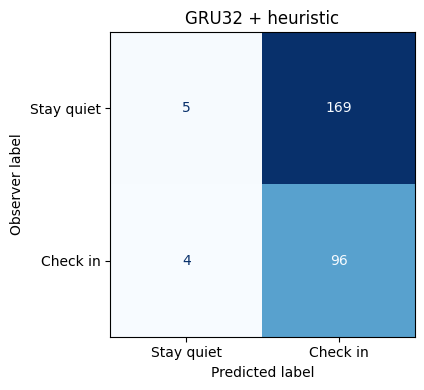

In [ ]:
# the boxes show the good calls and the mistakes
fig, ax = plt.subplots(figsize=(5, 4))

ConfusionMatrixDisplay.from_predictions(
    y,
    hybrid_decisions,
    labels=[0, 1],
    display_labels=['Stay quiet', 'Check in'],
    cmap='Blues',
    colorbar=False,
    ax=ax
)

ax.set_title('GRU32 + heuristic')
ax.set_ylabel('Observer label')

fig.tight_layout()
fig.savefig(RESULTS / 'evaluation.png', dpi=160)
plt.show()

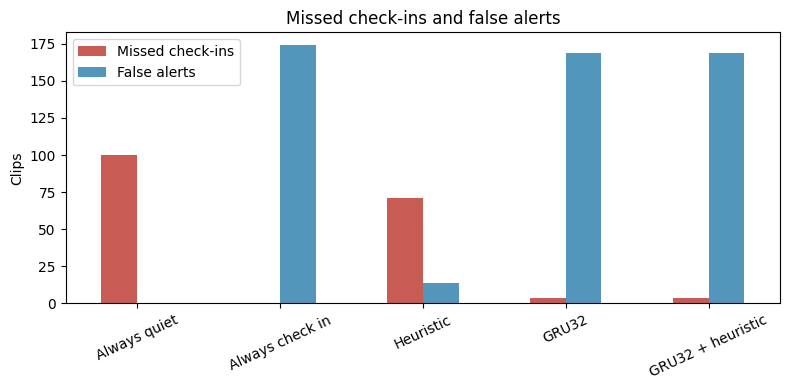

In [ ]:
# red is missed check-ins, blue is extra alerts
fig, ax = plt.subplots(figsize=(8, 4))

metrics[['missed_checkins', 'false_alerts']].plot.bar(
    ax=ax,
    color=['#c95b55', '#5296bc'],
    rot=25
)

ax.set_title('Missed check-ins and false alerts')
ax.set_xlabel('')
ax.set_ylabel('Clips')
ax.legend(['Missed check-ins', 'False alerts'])

fig.tight_layout()
fig.savefig(RESULTS / 'misses_and_alerts.png', dpi=160)
plt.show()

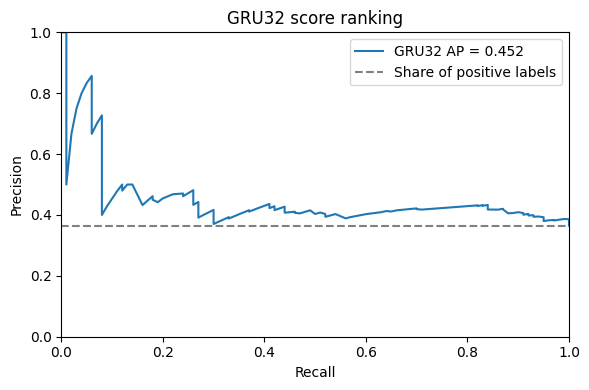

In [ ]:
# this checks how well the GRU scores put check-in cases ahead of quiet ones
precision, recall, _ = precision_recall_curve(y, saved_scores)
average_precision = average_precision_score(y, saved_scores)

fig, ax = plt.subplots(figsize=(6, 4))

ax.plot(recall, precision, label=f'GRU32 AP = {average_precision:.3f}')
ax.axhline(y.mean(), color='gray', linestyle='--', label='Share of positive labels')

ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('GRU32 score ranking')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend()

fig.tight_layout()
fig.savefig(RESULTS / 'precision_recall.png', dpi=160)
plt.show()

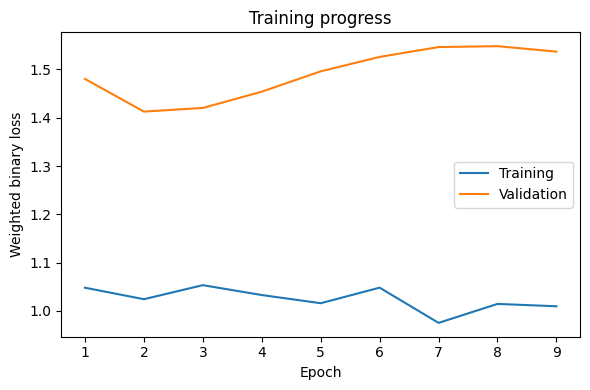

In [ ]:
# lower loss means fewer mistakes in the training objective
# this graph is from the first round, using seed 42
fig, ax = plt.subplots(figsize=(6, 4))

ax.plot(training_history['epoch'], training_history['training_loss'], label='Training')
ax.plot(training_history['epoch'], training_history['validation_loss'], label='Validation')

ax.set_xlabel('Epoch')
ax.set_ylabel('Weighted binary loss')
ax.set_title('Training progress')
ax.legend()

fig.tight_layout()
fig.savefig(RESULTS / 'training_curve.png', dpi=160)
plt.show()

The last model still picks its cutoff using students it didn't learn from.
The output has `step_in` and `intervention_level`. Right now 0 means quiet and
1 means a gentle check-in. Levels 2 and 3 aren't trained yet.
`step_in` is just `level > 0`, not a second thing the model learns.

In [ ]:
# puting the results together so we can look at them later
predictions = data[['clip_id', 'subject', 'split']].copy()
predictions['observer_target'] = y
predictions['fold'] = saved_folds
predictions['gru_score'] = saved_scores
predictions['threshold'] = saved_cutoffs
predictions['gru_decision'] = gru_decisions
predictions['heuristic_decision'] = rule
predictions['intervention_level'] = hybrid_decisions

# this is just a true/false flag made from the level
predictions['step_in'] = hybrid_decisions > 0
predictions.to_csv(RESULTS / 'predictions.csv', index=False, float_format='%.17g')
metrics.to_csv(RESULTS / 'metrics.csv')
pd.DataFrame(split_rows).to_csv(RESULTS / 'student_splits.csv', index=False)
training_history.to_csv(RESULTS / 'training_history.csv', index=False)

In [ ]:
train_rows, tuning_rows, cutoff_rows = make_student_groups(y, students, SEED + 9000)
final_models, final_epochs, _ = train_three_models(train_rows, tuning_rows)
final_cutoff = pick_cutoff(y[cutoff_rows], predict_scores(final_models, X[cutoff_rows]))

# save the trained weights and the cutoff
torch.save(
    {
        'state_dicts': [model.state_dict() for model in final_models],
        'threshold': final_cutoff,
        'feature_order': EMOTIONS,
        'score_max': 3,
        'hidden_size': 32,
        'timesteps': 1,
        'seeds': SEEDS,
        'epochs': final_epochs,
        'rule': 'confusion >= 2 or frustration >= 2',
        'levels_trained': [0, 1],
    },
    RESULTS / 'model.pt',
)

In [ ]:
settings = {
    'data_path': str(DATA_PATH),
    'labels_path': str(LABELS_PATH),
    'rows': len(data),
    'students': int(data.subject.nunique()),
    'target_recall': TARGET_RECALL,
    'miss_cost': MISS_COST,
    'final_threshold': final_cutoff,
    'seeds': SEEDS,
    'calibration_clip_ids': data.clip_id.iloc[cutoff_rows].tolist(),
    'evaluation': 'student-grouped development rerun; not fresh confirmation',
}
(RESULTS / 'settings.json').write_text(json.dumps(settings, indent=2), encoding='utf-8')
print('Saved results to:', RESULTS)

Saved results to: /content/drive/MyDrive/TriAid/simple_gru_results/20261115_095511


In [ ]:
# this is the bit the llm model will use
def predict_intervention(emotional_scores):

    # the order is boredom, engagement, confusion, frustration
    values = np.asarray(emotional_scores, dtype=np.float32)

    if (
        values.shape != (4,)
        or not np.isfinite(values).all()
        or (values < 0).any()
        or (values > 3).any()
    ):
        raise ValueError(
            'Use [boredom, engagement, confusion, frustration], each from 0 to 3.'
        )
    score = predict_scores(final_models, values[None] / 3.0)[0]
    rule_trigger = values[2] >= 2 or values[3] >= 2

    # for now the level is only 0 or 1
    level = int(score >= final_cutoff or rule_trigger)

    # anything above 0 tells the LLM side it can respond
    return {'step_in': level > 0, 'intervention_level': level}

In [ ]:
# testing
example = data[EMOTIONS].iloc[0].to_numpy(dtype=np.float32)
print('Input:', example)
print('Output:', predict_intervention(example))

Input: [0. 2. 2. 0.]
Output: {'step_in': True, 'intervention_level': 1}


In [ ]:
# one zip of the results
results_zip = RESULTS.with_suffix('.zip')

with ZipFile(results_zip, 'w', compression=ZIP_DEFLATED) as archive:

    for file in RESULTS.iterdir():
        archive.write(file, arcname=file.name)
print('Final Results:', results_zip)

Final Results: /content/drive/MyDrive/TriAid/simple_gru_results/20261115_095511.zip
